In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sqlalchemy import create_engine, text

engine = create_engine(
    "postgresql+psycopg://ektar@localhost:5432/olist_analytics"
)

with engine.connect() as connection:
    database_name = connection.execute(text("SELECT current_database()")).scalar_one()

print(database_name)

olist_analytics


In [3]:
from pathlib import Path

sql_queries = Path('../sql/03_business_metrics.sql').read_text(encoding="utf-8").split(';')

In [4]:
with engine.connect() as conn, conn.begin():
    monthly_sales = pd.read_sql_query(
        sql_queries[0],
        conn
    )

In [5]:
monthly_sales.head()

,purchase_month,delivered_order_count,delivered_items_total,avg_delivered_order_items_total
0,2016-09-01,1,134.97,134.970000
1,2016-10-01,265,40325.11,152.170226
2,2016-12-01,1,10.90,10.900000
3,2017-01-01,750,111798.36,149.064480
4,2017-02-01,1653,234223.40,141.695947


In [6]:
expected_months = pd.date_range(
    start=monthly_sales['purchase_month'].min(), 
    end=monthly_sales['purchase_month'].max(),
    freq='MS',
    name='purchase_month'
)

In [7]:
expected_months.difference(monthly_sales['purchase_month'])

DatetimeIndex(['2016-11-01'], dtype='datetime64[us]', name='purchase_month',
              freq='MS')

In [8]:
monthly_sales_comparable = monthly_sales.query("purchase_month >= '2017-02-01' and purchase_month < '2018-09-01'")

Text(0.5, 0, 'Месяц покупки')

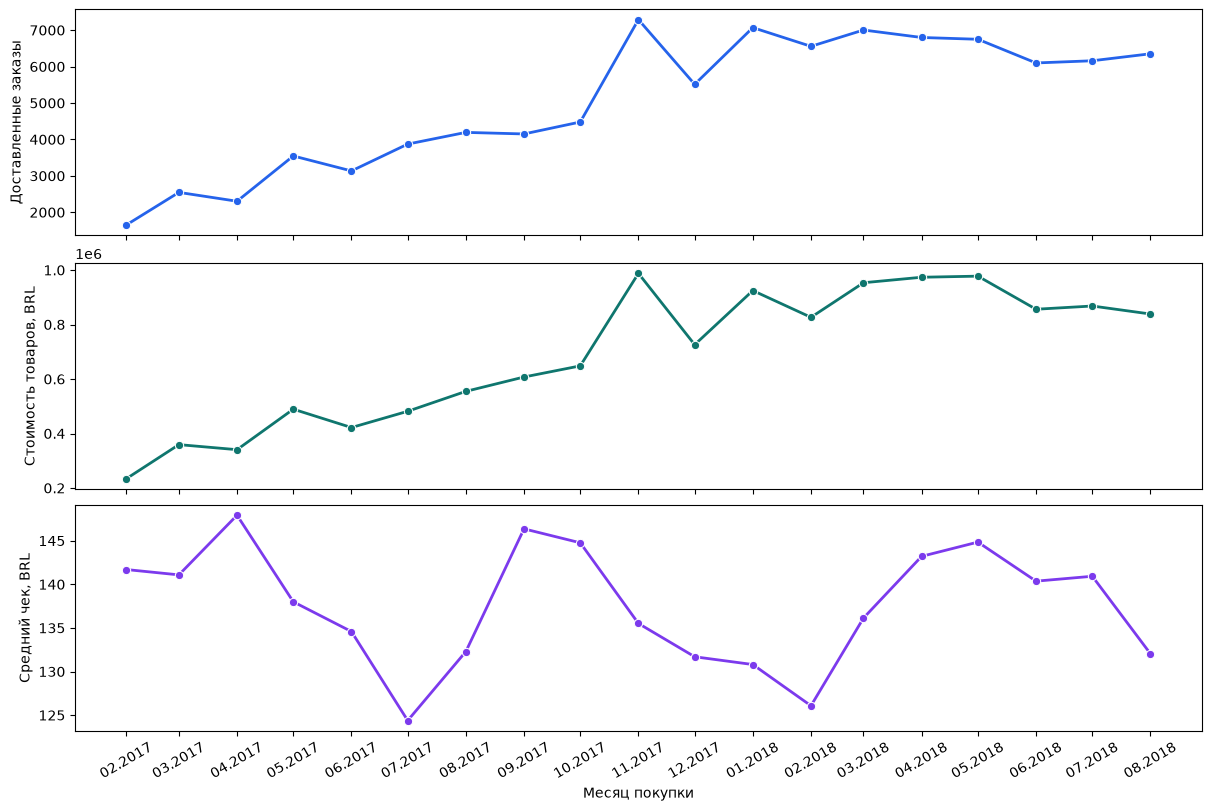

In [9]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(
    3, 1, 
    sharex=True,
    figsize=(12, 8),
    layout='constrained'
)

sns.lineplot(
    data=monthly_sales_comparable,
    x='purchase_month',
    y='delivered_order_count',
    color='#2563EB',
    marker='o',
    linewidth=2,
    ax=axes[0]
)

sns.lineplot(
    data=monthly_sales_comparable,
    x='purchase_month',
    y='delivered_items_total',
    color="#0F766E",
    marker='o',
    linewidth=2,
    ax=axes[1]
)
sns.lineplot(
    data=monthly_sales_comparable,
    x='purchase_month',
    y='avg_delivered_order_items_total',
    color='#7C3AED',
    marker='o',
    linewidth=2,
    ax=axes[2]
)

axes[0].set_ylabel('Доставленные заказы')
axes[1].set_ylabel('Стоимость товаров, BRL')
axes[2].set_ylabel('Средний чек, BRL')

axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=1))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
axes[-1].tick_params(axis="x", labelrotation=30)
axes[-1].set_xlabel("Месяц покупки")

In [10]:
month_comparison = (monthly_sales
    .set_index('purchase_month')
    .query("purchase_month >= '2017-10-01' and purchase_month <= '2017-11-01'")
    .sort_index()
)

month_over_month_pct = month_comparison.pct_change().mul(100).round(2)

month_comparison

,delivered_order_count,delivered_items_total,avg_delivered_order_items_total
purchase_month,,,
2017-10-01,4478,648247.65,144.762762
2017-11-01,7289,987765.37,135.514525


In [11]:
month_over_month_pct

,delivered_order_count,delivered_items_total,avg_delivered_order_items_total
purchase_month,,,
2017-10-01,NaN,NaN,NaN
2017-11-01,62.77,52.37,-6.39


С октября по ноябрь 2017 года стоимость товаров выросла на 52,37%. Число доставленных заказов выросло на 62,77%, перекрыв снижение среднего чека на 6,39%. Стоимость товаров выросла за счет увеличения числа доставленных заказов, несмотря на снижение среднего чека.